# chip_03_trilayer — nine Xmons and ten λ/4 resonators on one feedline (Nb trilayer), on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_03_trilayer.py` (`create_chip(5)`; "Trilayer new design for more qubits",
WRIDHDHI, May 2024; writes `chip_03_TL_5.gds`), Quantcore internal. Spec: `docs/designs/legacy/chip_03_trilayer.md`.

A 7.5 × 7.5 mm die: one 10/6 µm CPW feedline between two rounded 600 × 200 µm connector pads; ten λ/4
`Coupled Resonator` meanders (10/10 µm CPW, 200 µm coupler behind a 7 µm ground strip, 4120–6790 µm for 4.5–7.5
GHz), five above and five below the feedline; nine `Xmon Cross` qubits (two with 600 µm crosses) whose claws
take the resonator tails; trilayer junctions with 0.8 or 0.5 µm straight fingers and a 0.5 µm second finger;
eight 4 × 15 arrays of 20 µm flux-trap holes; R7 has no qubit.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| resonators, Xmons | the ten `Coupled Resonator`s and nine `Xmon Cross`es with the legacy parameters, legacy x and rotation; each claw joined to its resonator's open end; R7 uncut with its own open end (#26) | — |
| feedline, pads | rounded 600 × 200 µm "Connector Pad" geometry (`ConnectorPad`), 10/6 µm CPW (`CpwSegment`) | pads with their outer etch **`pad_edge` = 100 µm** from the die edge (legacy: at the edge): feedline 5360 → 5160 µm |
| junctions | the author's first-generation HSQ trilayer cell (`Trilayer Junction HSQ`) at the legacy fingers (js · 0.1 × 0.5 µm), the design decision | valued on the PDK process: R_n 54 kΩ (js 5) and 33.75 kΩ (js 8), outside the 40–50 kΩ window → **flagged** (`pdk_rn`), not retuned |
| cheese | the source's own eight 4 × 15 arrays of 20 µm holes (`FluxHoleArray`) | the source's holes stay, and the PDK cheese covers the rest of the die (`cheese: "chip"`: 5 µm squares with 20 µm gaps, at least 4 µm from the 3/0 keep-outs, which cover every structure and hole array, so no PDK hole touches one) |
| placement | everything relative to the feedline | the circuit **centred in the die** (step 6) |
| frame | — | the PDK die frame and device ID `QCG_Nb03_W` (the source's label) instead of the legacy corner markers; the "TOP=500nm" label is not drawn |

**Reproduced exactly** (XOR against the author's own PCells, read-only through `tests/legacy_ref`, step 14): the
resonators, the Xmon crosses and claws (at the corrected positions), the flux-hole arrays, and the pads +
feedline at their PDK position. The junction windows differ (legacy CLEARER 30 × 27 µm boxes are not cleared
from 1/0 by this cell).

### Changes after design review (2026-11-03)

- **#8 resonator tails ↔ Xmon claws — geometry corrected** (review note: "the resonator tail protrudes into the xmon claw;
  correct the geometry"). As drawn, seven tails ended 46–56 µm past the claw tip with the PCell's end cap (`ground=True`),
  which cut the claw off (a floating claw, coupled only across the cap), and the tails of **R6 and R8 ran 414 µm in,
  through the claw and the cross arm, splitting Q6's and Q8's islands** (FEM nets `Qi.island` + `Qi.island#2`). Now every qubit resonator ends **without a gap cap**
  (`ground=False`, the legacy `Coupled Resonator`'s own "xmon connector" mode, as in the author's later chips 05 and 10a)
  and its Xmon is **snapped with the claw-tail tip onto that end** (`snap="claw_n", to="Ri.end"`): the claw is the
  λ/4's open end, galvanically. Each Xmon keeps its x and rotation and moves along the tail axis only (table after the
  layout cell). The line now also includes the claw's 50 µm tail stub.
- **#26 R7 — no cut.** The legacy `resonatorGnd` box (CUT7) etched R7's tail 372.5 µm before its end, leaving a
  6417.5 µm λ/4 and a floating 355 µm stub. The user: the cut is not intended; the later PCell has a dedicated open
  and short end. R7 (no qubit) is now the full **6790 µm** line with the PCell's own open end (`ground=True`: gap cap
  at the far end, shorted at the coupler) — no CUT7 box, no floating stub (`R7S`, `CAP7` and the `W_R7` wire are gone).
- **#1 / PDK rebuild — junctions.** The Xmons keep the author's first-generation HSQ trilayer cell (`Trilayer Junction
  HSQ`: fingers on 2/0 + 4/0, spacer 50/0 with the 51–53/0 gradient), now drawn at the **legacy fingers** (js·0.1 ×
  0.5 µm through `junction_params`; before, the cell's default fingers were drawn and only the LOM used the legacy
  sizes) and valued on the **PDK junction rule** (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV; PDK process
  R_n·A 13.5 kΩ·µm², assumed by the PDK, = 45 kΩ at the PDK's 0.5 × 0.6 µm): js 5 (0.25 µm²: Q2, Q6, Q9–Q12) →
  R_n = 54 kΩ, js 8 (0.40 µm²: Q1, Q5, Q8) → 33.75 kΩ — just outside the 40–50 kΩ on both sides (a 0.6 µm bent
  finger, the PDK default, would put js 5 at 45 kΩ; design decision). The earlier assumed J_c = 1 µA/µm² is gone.
  Values in section 4.
- **Claw-tail gap (#22):** the Xmon's claw tail is now cleared by its own `claw_tail_gap` (default: the chip CPW gap, 6 µm); `L.xmon` sets it to the legacy `cap_spacing` = 10 µm, as the legacy
  `Xmon Cross` draws it, matching the 10/10 µm resonators.
- **Not re-executed here** (verification policy for this pass): the saved JSON is rebuilt from the layout
  cell, the outputs are cleared; run the notebook to regenerate the tables and PNGs.

### PDK conformance pass (notebooks-legacy, 2026-11-10)

- **Pads:** the left pad is placed with `edge="auto"` (outer etch `get_pdk().frame.pad_edge` = 100 µm from the
  die edge), the feedline snaps onto its port with the length the rule leaves on a symmetric chip, and the right
  pad snaps onto the far end. (The legacy feedline overlapped the pads' CPW stubs by 50 µm with identical CPW;
  the rebuild's pads snap to the feedline ends, which gives the same etch.) DRC `pad_edge` warnings: 2 → 0.
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off).
- **Cheese:** the PDK cheese over the whole die (`cheese: "chip"`): 5 µm squares with 20 µm gaps wherever the ground is at least 4 µm from the 3/0 keep-outs, which cover every structure, so no hole touches one; the source's own flux holes stay as drawn.
- **Junctions:** the author's HSQ trilayer cells at the legacy fingers (decision #1); their R_n is flagged by
  `pdk_rn` where it leaves 40–50 kΩ, never retuned.
- Educative layout: one step per stage (die → pads and feedline → resonators and Xmons → holes and centring →
  DRC → LOM → FEM → iterate → export → snapshots).

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_03_trilayer", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 13) and the centring of the content (step 6).

In [3]:
CHEESE_NOTE = 'chip — the PDK cheese over the whole die; the eight 4 × 15 arrays of 20 µm flux holes the source etches (FluxHoleArray) stay'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: original — the source etches eight 4 × 15 arrays of 20 µm flux holes (FluxHoleArray); no PDK band |

### The source's numbers

`chip_03_trilayer.py`'s numbers in its own (0, 0)-centred frame (µm); `L.place` shifts them by (+3750, +3750)
into the Designer frame; `L.xmon`, `L.coupled_resonator`, `L.connector_pad`, `L.cpw_segment` map the legacy PCell
parameters. Each row: resonator, its coupler position, length and target frequency (the source's comment), and
its Xmon (legacy centre, rotation, 600 µm cross or not, junction scale js).

In [4]:
SIZE = 5                     # create_chip(5): second junction finger 0.5·SIZE/5 µm, label "TOP=500nm"
# chip_03_trilayer.py, legacy frame (µm)
FEED = dict(length=7500 - 2000 - 40, lc_thickness=2, rc_thickness=2)                 # "Coplanar Waveguide"
PAD = dict(trace_width=10, pad_height=200, pad_width=600, conn_height=500, round=True, sim=False)
RES = dict(gap=10, clength=200, cgap=7, width=250, neck_length=400)                  # "Coupled Resonator"
#   qubit resonators: ground=False (no end cap, the PCell's "xmon connector" end, joined to the claw tip, #8);
#   R7 (no qubit): ground=True, the PCell's own open end (#26: no CUT7 cut, no floating stub)
XMON = dict(width=400, handle=1, cap_spacing=10, da=3, thickness=50, pthickness=30, fwidth=30, spacing=20, ggap=15)
BIG = XMON | dict(width=600)
#        n     x_res y_res mirror cpw_len flip  f (GHz) Xmon: (x, y, rot, big, js) or None   (x, y: legacy, see #8)
ROWS = [("1",  -2200,  33, True,  4740, False, 6.5,  (-2175,  2225, 2, True,  8)),
        ("2",  -2200, -33, False, 4410, True,  7.0,  (-2225, -2157, 0, False, 5)),
        ("5",  -1050,  33, True,  5840, False, 5.25, (-1025,  2507, 2, False, 8)),
        ("6",  -1050, -33, False, 6200, True,  5.0,  (-1075, -2508, 0, False, 5)),
        ("7",     50,  33, True,  6790, True,  4.5,  None),                       # no Xmon: bare λ/4, own open end
        ("8",     50, -33, False, 5590, False, 5.5,  (   75, -2257, 0, False, 8)),
        ("9",   1150,  33, True,  5340, False, 5.75, ( 1175,  2375, 2, False, 5)),
        ("10",  1150, -33, False, 5200, True,  6.0,  ( 1125, -2225, 0, False, 5)),
        ("11",  2200,  33, True,  4410, True,  7.0,  ( 2175,  2254, 2, True,  5)),
        ("12",  2200, -33, False, 4120, False, 7.5,  ( 2225, -1864, 0, False, 5))]
HOLES_X = [-2200, -1075, -15, 1075]  # flux_holes: 4 × 15 squares of 20 µm, 100 µm pitch, at (x + 450, 300 | -1800)
SECOND_FINGER = 0.5 * SIZE / 5

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die. The PDK frame is drawn on every build: four L-shaped
dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the device ID, here the
source's own chip label `QCG_Nb03_W`. `cheese="chip"`: the build draws the PDK cheese over the whole die, at least 4 µm from the 3/0 keep-outs; the design's own cheese, the flux holes (step 6), stays as drawn.

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


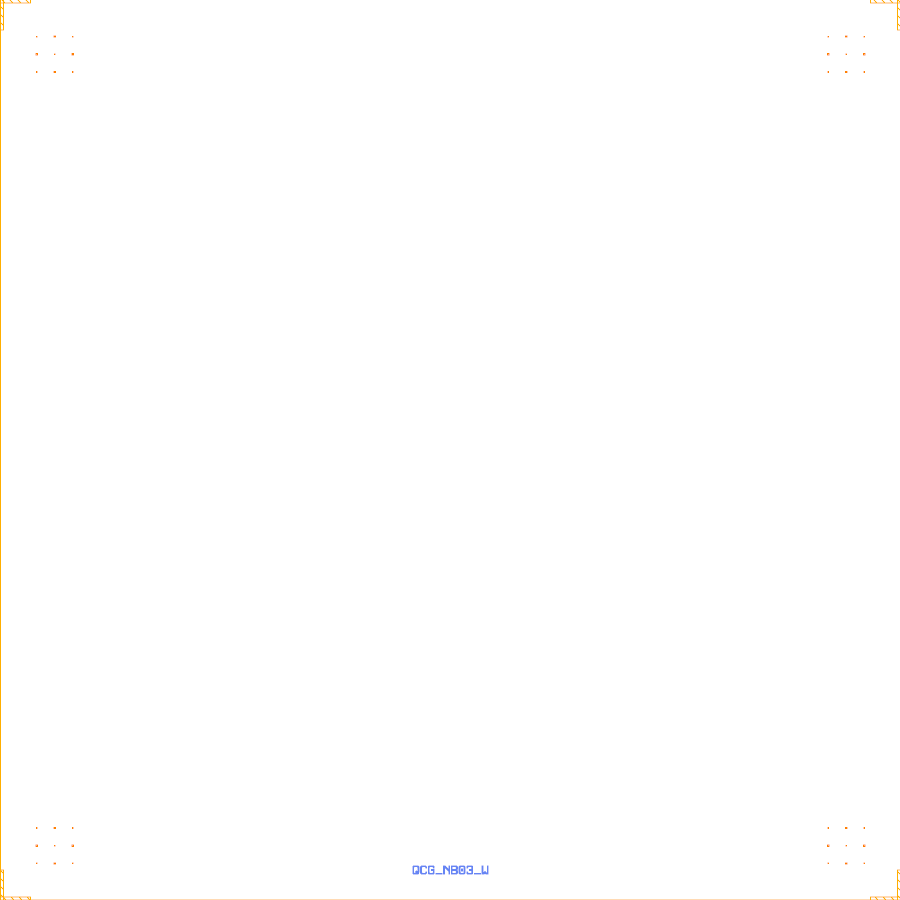

WindowsPath('build/legacy_steps/chip_03_trilayer_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "QCG_Nb03_W", "cheese": "chip"}, live=LIVE)
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule) and the feedline

The rounded legacy "Connector Pad" (`ConnectorPad`: 600 × 200 µm pad, 500 µm taper) goes at the left end of the
feedline with the legacy rotation (rot 3); `edge="auto"` slides it perpendicular to its nearest die edge until the
outer edge of its etch is **`pad_edge` = 100 µm** from the die edge (`get_pdk().frame.pad_edge`, the design-area
margin): the PDK pad rule, which wins over the original (whose rounded pads reached the die edge).

The feedline (`CpwSegment`, 10/6 µm) snaps onto the left pad's port with the length the rule leaves on this
symmetric chip (die width − 2 × the port's x), and the right pad snaps onto its far end: pad, feedline and pad are
one conductor in the netlist. `L.edge_gaps` measures both pads from the built etch. The feedline still spans all
ten couplers (legacy x = −2300 … +2300).

pad etch → die edge (µm): {'PL': 100.0, 'PR': 100.0} | rule: 100.0
feedline 5160 µm (legacy drawn 5460 µm overlapping the pads' stubs; 5360 µm between the pad tips)


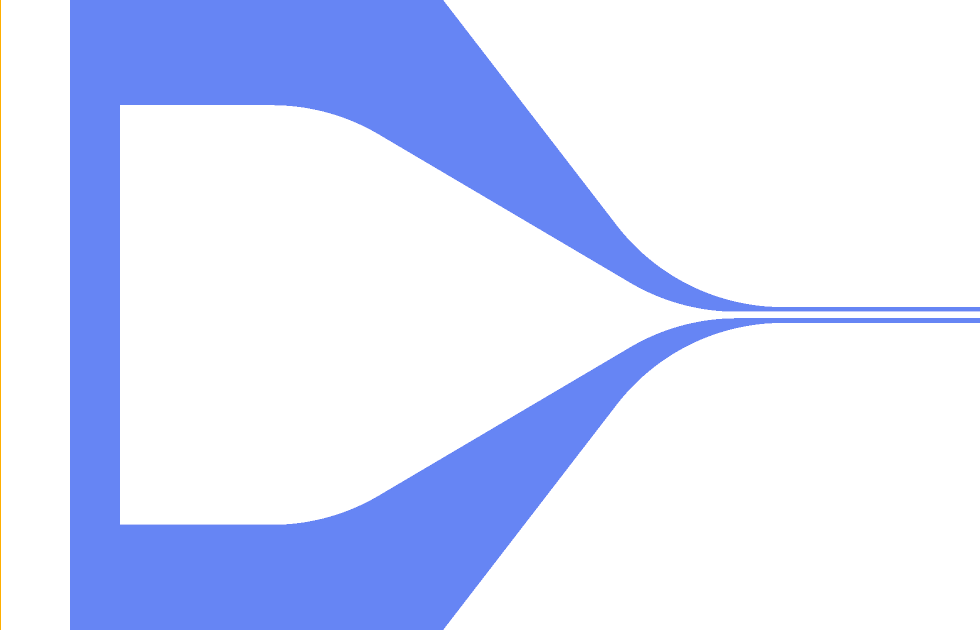

WindowsPath('build/legacy_steps/chip_03_trilayer_2_pads.png')

In [6]:
d.add("PL", "ConnectorPad", **L.place(-2500, 0, 3), edge="auto", **L.connector_pad(**PAD))   # legacy (−2680, 0), rot 3
x_pad = L.W / 2 - C.port_xy(d, "PL.a")[0]          # feedline half-length the rule leaves (legacy frame)
with d.batch():
    d.add("FL", "CpwSegment", snap="a", to="PL.a", **L.cpw_segment(**FEED | {"length": round(2 * x_pad, 3)}))
    d.add("PR", "ConnectorPad", snap="a", to="FL.b", **L.connector_pad(**PAD))   # legacy (+2680, 0), rot 1
print("pad etch → die edge (µm):", L.edge_gaps(d), "| rule:", get_pdk().frame.pad_edge)
print(f"feedline {2 * x_pad:.0f} µm (legacy drawn 5460 µm overlapping the pads' stubs; 5360 µm between the pad tips)")
L.step_snapshot(d, "2_pads", box=(0, 3300, 1400, 4200), size=(980, 630), width=490)

## 5 · Components: resonators, Xmons and their junctions

Each `CoupledResonator` is the legacy `Coupled Resonator` PCell: a meandered 10/10 µm λ/4 (`cpw_len`), shorted at
the end of a 200 µm coupler beside the feedline behind a 7 µm ground strip. The nine qubit resonators end
**uncapped** (`ground=False`) and their `Xmon` is **snapped with its claw-tail tip onto that end**
(`snap="claw_n", to="Ri.end"`): the claw is the resonator's open end, galvanically. R7 (no qubit) is the full
6790 µm line with the PCell's own open end (`ground=True`). `d.couple("K_Ri", "Ri", "FL")` declares
the coupler ∥ feedline coupling (a hanger κ in the netlist); `d.targets` stores the source's frequencies.

**Junctions.** Each Xmon draws the author's first-generation HSQ trilayer cell `Trilayer Junction HSQ` (fingers on
2/0 + 4/0, spacer 50/0 with the 51–53/0 gradient) at the **legacy fingers**, js · 0.1 µm × 0.5 µm
(`junction_params`), as the design decision keeps it. `L.jj` values the drawn fingers on the PDK process (R_n·A
13.5 kΩ·µm²): js 5 (0.25 µm²) → 54 kΩ, js 8 (0.40 µm²) → 33.75 kΩ, both outside the PDK's 40–50 kΩ, so DRC flags
them (`pdk_rn`, step 7) — flagged, never retuned.

| pair | legacy Xmon centre (legacy frame) | corrected Xmon centre | moved by (µm) | gap claw tip ↔ tail end |
|---|---|---|---|---|
| Q1/R1 | (-2175, 2225) | (-2175.0, 2279.9) | Δx +0.0, Δy +54.9 | -0.000 µm |
| Q2/R2 | (-2225, -2157) | (-2225.0, -2208.9) | Δx +0.0, Δy -51.9 | 0.000 µm |
| Q5/R5 | (-1025, 2507) | (-1025.0, 2561.8) | Δx +0.0, Δy +54.8 | -0.000 µm |
| Q6/R6 | (-1075, -2508) | (-1075.0, -2921.8) | Δx +0.0, Δy -413.8 | 0.000 µm |
| Q8/R8 | (75, -2257) | (75.0, -2670.9) | Δx +0.0, Δy -413.9 | 0.000 µm |
| Q9/R9 | (1175, 2375) | (1175.0, 2420.9) | Δx +0.0, Δy +45.9 | -0.000 µm |
| Q10/R10 | (1125, -2225) | (1125.0, -2280.9) | Δx +0.0, Δy -55.9 | 0.000 µm |
| Q11/R11 | (2175, 2254) | (2175.0, 2308.9) | Δx +0.0, Δy +54.9 | -0.000 µm |
| Q12/R12 | (2225, -1864) | (2225.0, -1918.9) | Δx +0.0, Δy -54.9 | 0.000 µm |

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).


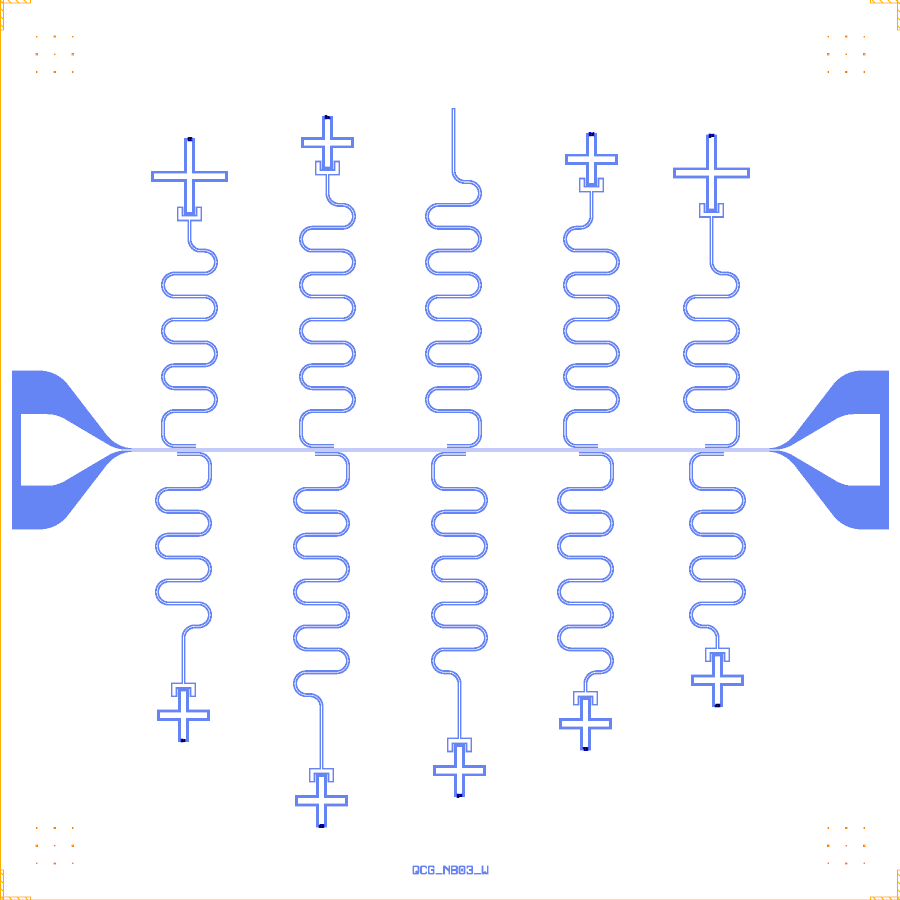

WindowsPath('build/legacy_steps/chip_03_trilayer_3_components.png')

In [7]:
with d.batch():
    for n, x, y, mirror, length, flip, f, q in ROWS:
        d.add(f"R{n}", "CoupledResonator", **L.place(x, y, 0, mirror),
              **L.coupled_resonator(**RES | {"ground": q is None}, cpw_len=length, flip=flip))
        d.couple(f"K_R{n}", f"R{n}", "FL", note="200 µm coupler parallel to the feedline, 7 µm ground strip")
        d.targets(**{f"R{n}": {"f_GHz": f}})
        if q:
            xq, yq, rot, big, js = q     # #8: claw-tail tip snapped onto the uncapped tail end (legacy centre xq, yq)
            d.add(f"Q{n}", "Xmon", snap="claw_n", to=f"R{n}.end", **L.xmon(**(BIG if big else XMON)),
                  junction_type="Trilayer Junction HSQ",       # legacy fingers js · 0.1 × 0.5 µm
                  junction_params={"finger_width": 0.1 * js, "second_finger_width": SECOND_FINGER},
                  junction=L.jj(0.1 * js, SECOND_FINGER))      # PDK process values
            d.sim_group(f"Q{n}R{n}", [f"Q{n}", f"R{n}"])
display(Markdown(L.claw_join_md(d, [(f"Q{n}", f"R{n}", q[:2]) for n, *_, q in ROWS if q])))
print(L.rule_md())
L.step_snapshot(d, "3_components")

## 6 · The source's cheese, and centring

**Cheese — the source's holes and the PDK cheese.** The source etches its own flux-trapping holes: eight arrays of 4 × 15 squares
of 20 µm on a 100 µm pitch, above and below the feedline between the resonators (`FluxHoleArray`, drawn on 1/0).
They stay as drawn; the chip's `cheese="chip"` (step 3) adds the PDK squares over the rest of the die, at least 4 µm from the 3/0 keep-outs (which cover the hole arrays too), so no PDK hole touches a structure or a flux hole. No routes: like the legacy chip it is
drawn from fixed cells whose ports touch.

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances and routes) and shifts the
design so it sits in the middle of the die (each axis only if > 50 µm off). Then the design is saved.

centring shift (µm): (0.0, 146.0) | feedline y = 3896.0 | <Designer chip_03_trilayer: 30 instances, 0 routes, live=False> → examples\designs\legacy\chip_03_trilayer.json


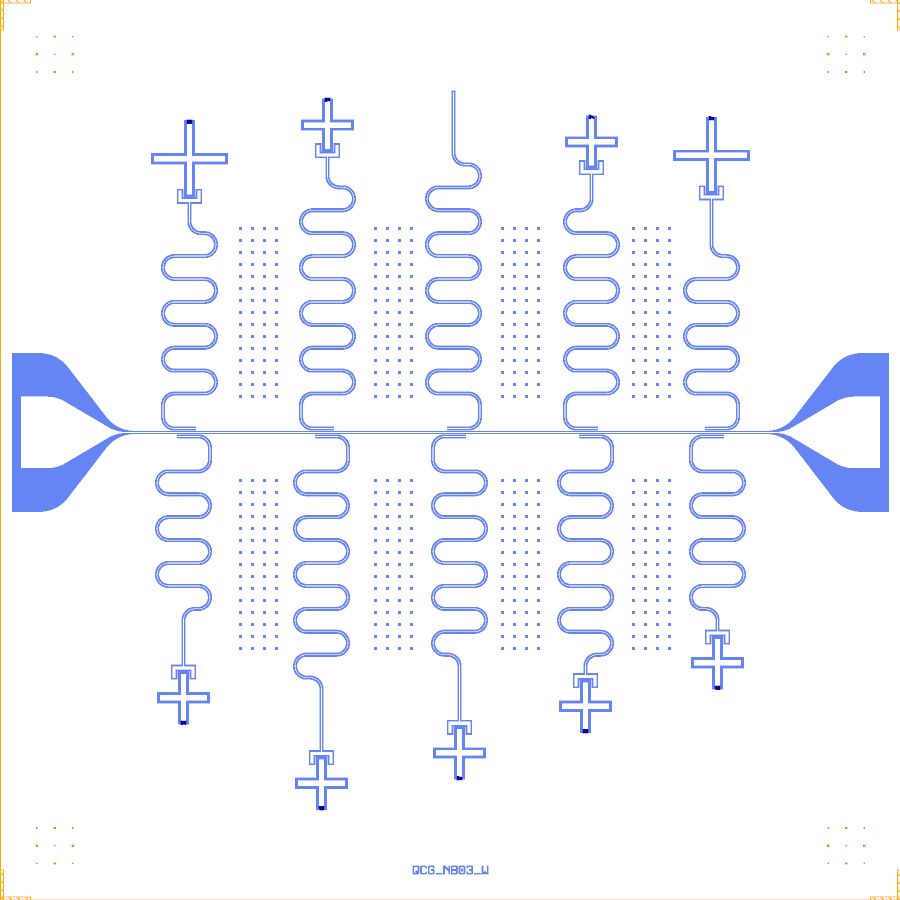

WindowsPath('build/legacy_steps/chip_03_trilayer_4_centred.png')

In [8]:
with d.batch():
    for k, x in enumerate(HOLES_X):
        for side, y0 in (("N", 300), ("S", -1800)):
            d.add(f"H{k}{side}", "FluxHoleArray", **L.place(x + 450, y0),
                  hole_size=20, pitch_x=100, pitch_y=100, nx=4, ny=15)
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "| feedline y =", round(C.port_xy(d, "FL.a")[1], 1), "|", d, "→", DESIGN)
L.step_snapshot(d, "4_centred")

## 7 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip) must be fixed; **warnings** are reported for a person to judge (a dangling open end,
two cells' bounding boxes touching); **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag
values outside the PDK margins — they are never retuned for, only listed. `C.pdk_report(d)` summarises the
PDK checks: cheese source, content centring, junction types and the design warnings.

Expected: zero errors; `dangling_port` `R7.end` (R7's own open end, nothing joins it by design); **9 PDK design
warnings** `pdk_rn`: the legacy fingers on the PDK process give 33.7 kΩ (js 8: Q1, Q5, Q8) and 54.0 kΩ (js 5: Q2,
Q6, Q9–Q12), outside 40–50 kΩ — flagged, not retuned (the design decision keeps the legacy fingers). `pdk_report`:
cheese "PDK cheese over the whole die (drawn in the build)", content centre (+0, −0) µm, junction types `Trilayer Junction HSQ` × 9.

In [9]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port R7.end is not connected (no route or snap)
design  pdk_rn        Q1: junction R_n 33.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.0508 nH)
design  pdk_rn        Q2: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH)
design  pdk_rn        Q5: junction R_n 33.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.0508 nH)
design  pdk_rn        Q6: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH)
design  pdk_rn        Q8: junction R_n 33.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.0508 nH)
design  pdk_rn        Q9: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH)
design  pdk_rn        Q10: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH)
design  pdk_rn        Q11: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH)
design  pdk_rn        Q12: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH)


| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, -0) µm |
| junction types | Trilayer Junction HSQ × 9 |
| PDK design warnings | 9 (pdk_rn × 9) |
| pdk_rn | Q1: junction R_n 33.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.0508 nH) |
| pdk_rn | Q2: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH) |
| pdk_rn | Q5: junction R_n 33.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.0508 nH) |
| pdk_rn | Q6: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH) |
| pdk_rn | Q8: junction R_n 33.7 kΩ is outside the PDK window 40–50 kΩ (L_J 5.0508 nH) |
| pdk_rn | Q9: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH) |
| pdk_rn | Q10: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH) |
| pdk_rn | Q11: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH) |
| pdk_rn | Q12: junction R_n 54.0 kΩ is outside the PDK window 40–50 kΩ (L_J 8.0813 nH) |

## 8 · Netlist and LOM

`FL.line` joins both snapped pads (a 50 Ω port each). Each `CoupledResonator` → a λ/4 `TLres` (shorted at its
coupler) with a `HANGER` κ to the feedline; the nine qubit resonators end on their Xmon's claw node (snapped: one
conductor; C_g to the island, C to ground; the island carries C and the junction). R7 is a bare 6790 µm λ/4 with
its own open end. The flux-hole arrays have no circuit role.

In [10]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**21 nodes · 58 branches · 0 controls · 1 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL.line` | `PL.pad`, `FL.line`, `PR.pad` |
| `R1.res` | `R1.res`, `Q1.claw_n` |
| `Q1` | `Q1.island` |
| `R2.res` | `R2.res`, `Q2.claw_n` |
| `Q2` | `Q2.island` |
| `R5.res` | `R5.res`, `Q5.claw_n` |
| `Q5` | `Q5.island` |
| `R6.res` | `R6.res`, `Q6.claw_n` |
| `Q6` | `Q6.island` |
| `R7.res` | `R7.res` |
| `R8.res` | `R8.res`, `Q8.claw_n` |
| `Q8` | `Q8.island` |
| `R9.res` | `R9.res`, `Q9.claw_n` |
| `Q9` | `Q9.island` |
| `R10.res` | `R10.res`, `Q10.claw_n` |
| `Q10` | `Q10.island` |
| `R11.res` | `R11.res`, `Q11.claw_n` |
| `Q11` | `Q11.island` |
| `R12.res` | `R12.res`, `Q12.claw_n` |
| `Q12` | `Q12.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PL` | R | `FL.line` – `gnd` | 50 Ω |
| `Port_PR` | R | `FL.line` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 128 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 5.05 nH, Cj 20 fF |
| `Cg_Q1_claw_n` | C | `Q1` – `R1.res` | 3.17 fF |
| `Cc_Q1_claw_n` | C | `R1.res` – `gnd` | 76.4 fF |
| `C_Q2` | C | `Q2` – `gnd` | 85.4 fF |
| `J_Q2` | JJ | `Q2` – `gnd` | Lj 8.08 nH, Cj 12.5 fF |
| `Cg_Q2_claw_n` | C | `Q2` – `R2.res` | 3.17 fF |
| `Cc_Q2_claw_n` | C | `R2.res` – `gnd` | 76.4 fF |
| `C_Q5` | C | `Q5` – `gnd` | 85.4 fF |
| `J_Q5` | JJ | `Q5` – `gnd` | Lj 5.05 nH, Cj 20 fF |
| `Cg_Q5_claw_n` | C | `Q5` – `R5.res` | 3.17 fF |
| `Cc_Q5_claw_n` | C | `R5.res` – `gnd` | 76.4 fF |
| `C_Q6` | C | `Q6` – `gnd` | 85.4 fF |
| `J_Q6` | JJ | `Q6` – `gnd` | Lj 8.08 nH, Cj 12.5 fF |
| `Cg_Q6_claw_n` | C | `Q6` – `R6.res` | 3.17 fF |
| `Cc_Q6_claw_n` | C | `R6.res` – `gnd` | 76.4 fF |
| `C_Q8` | C | `Q8` – `gnd` | 85.4 fF |
| `J_Q8` | JJ | `Q8` – `gnd` | Lj 5.05 nH, Cj 20 fF |
| `Cg_Q8_claw_n` | C | `Q8` – `R8.res` | 3.17 fF |
| `Cc_Q8_claw_n` | C | `R8.res` – `gnd` | 76.4 fF |
| `C_Q9` | C | `Q9` – `gnd` | 85.4 fF |
| `J_Q9` | JJ | `Q9` – `gnd` | Lj 8.08 nH, Cj 12.5 fF |
| `Cg_Q9_claw_n` | C | `Q9` – `R9.res` | 3.17 fF |
| `Cc_Q9_claw_n` | C | `R9.res` – `gnd` | 76.4 fF |
| `C_Q10` | C | `Q10` – `gnd` | 85.4 fF |
| `J_Q10` | JJ | `Q10` – `gnd` | Lj 8.08 nH, Cj 12.5 fF |
| `Cg_Q10_claw_n` | C | `Q10` – `R10.res` | 3.17 fF |
| `Cc_Q10_claw_n` | C | `R10.res` – `gnd` | 76.4 fF |
| `C_Q11` | C | `Q11` – `gnd` | 128 fF |
| `J_Q11` | JJ | `Q11` – `gnd` | Lj 8.08 nH, Cj 12.5 fF |
| `Cg_Q11_claw_n` | C | `Q11` – `R11.res` | 3.17 fF |
| `Cc_Q11_claw_n` | C | `R11.res` – `gnd` | 76.4 fF |
| `C_Q12` | C | `Q12` – `gnd` | 85.4 fF |
| `J_Q12` | JJ | `Q12` – `gnd` | Lj 8.08 nH, Cj 12.5 fF |
| `Cg_Q12_claw_n` | C | `Q12` – `R12.res` | 3.17 fF |
| `Cc_Q12_claw_n` | C | `R12.res` – `gnd` | 76.4 fF |
| `R1` | TLres | `R1.res` – `gnd` | lambda/4, 4740 µm, 6.636 GHz |
| `K_R1` | HANGER | `R1.res` – `FL.line` | κ 0.0667 MHz (L 200 µm) |
| `R2` | TLres | `R2.res` – `gnd` | lambda/4, 4410 µm, 7.132 GHz |
| `K_R2` | HANGER | `R2.res` – `FL.line` | κ 0.0828 MHz (L 200 µm) |
| `R5` | TLres | `R5.res` – `gnd` | lambda/4, 5840 µm, 5.386 GHz |
| `K_R5` | HANGER | `R5.res` – `FL.line` | κ 0.0357 MHz (L 200 µm) |
| `R6` | TLres | `R6.res` – `gnd` | lambda/4, 6200 µm, 5.073 GHz |
| `K_R6` | HANGER | `R6.res` – `FL.line` | κ 0.0298 MHz (L 200 µm) |
| `R7` | TLres | `R7.res` – `gnd` | lambda/4, 6790 µm, 4.632 GHz |
| `K_R7` | HANGER | `R7.res` – `FL.line` | κ 0.0227 MHz (L 200 µm) |
| `R8` | TLres | `R8.res` – `gnd` | lambda/4, 5590 µm, 5.627 GHz |
| `K_R8` | HANGER | `R8.res` – `FL.line` | κ 0.0407 MHz (L 200 µm) |
| `R9` | TLres | `R9.res` – `gnd` | lambda/4, 5340 µm, 5.890 GHz |
| `K_R9` | HANGER | `R9.res` – `FL.line` | κ 0.0467 MHz (L 200 µm) |
| `R10` | TLres | `R10.res` – `gnd` | lambda/4, 5200 µm, 6.049 GHz |
| `K_R10` | HANGER | `R10.res` – `FL.line` | κ 0.0505 MHz (L 200 µm) |
| `R11` | TLres | `R11.res` – `gnd` | lambda/4, 4410 µm, 7.132 GHz |
| `K_R11` | HANGER | `R11.res` – `FL.line` | κ 0.0828 MHz (L 200 µm) |
| `R12` | TLres | `R12.res` – `gnd` | lambda/4, 4120 µm, 7.635 GHz |
| `K_R12` | HANGER | `R12.res` – `FL.line` | κ 0.102 MHz (L 200 µm) |

**Unconnected ports:** `R7.end`

{'nodes': 20, 'branches': 58, 'controls': 0, 'unconnected': 1}


## 9 · LOM simulation

One sub-circuit per qubit + resonator with the feedline and both pads (`C.simulate_groups`: QuCat normal modes →
QuTiP-dressed values), with the source's resonator frequencies as targets (in brackets). Values are component
estimates (Xmon calibration, CPW λ/4 on 10/10 µm, hanger κ) with the drawn junctions on the PDK process.

In [11]:
groups = {f"Q{n}+R{n}": [f"Q{n}", f"R{n}", "FL", "PL", "PR"] for n, *_, q in ROWS if q}
groups["R7"] = ["R7", "FL", "PL", "PR"]
results = C.simulate_groups(d, groups)
display(Markdown(C.groups_md(results, d.data["targets"])))
display(Markdown(L.junction_table([(f"Q{n} (js {q[4]})", 0.1 * q[4], SECOND_FINGER, 1) for n, *_, q in ROWS if q])))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+R1 | Q1 | 5.6215 | -131.2 | R1 | 5.885 (6.5) | 0.0382 | -3.95 |
| Q2+R2 | Q2 | 5.3679 | -208.3 | R2 | 6.2719 (7) | 0.0493 | -1.13 |
| Q5+R5 | Q5 | 6.6145 | -190.3 | R5 | 4.8707 (5.25) | 0.0239 | -0.169 |
| Q6+R6 | Q6 | 5.3721 | -208.3 | R6 | 4.6115 (5) | 0.0203 | -1.12 |
| Q8+R8 | Q8 | 6.6147 | -190.2 | R8 | 5.0678 (5.5) | 0.0267 | -0.246 |
| Q9+R9 | Q9 | 5.3868 | -273.9 | R9 | 5.2667 (5.75) | 0.0294 | 45.2 |
| Q10+R10 | Q10 | 5.4376 | -357.2 | R10 | 5.344 (6) | 0.0302 | 86.9 |
| Q11+R11 | Q11 | 4.5298 | -144.7 | R11 | 6.2699 (7) | 0.0494 | -0.166 |
| Q12+R12 | Q12 | 5.3685 | -208.7 | R12 | 6.6595 (7.5) | 0.0587 | -0.695 |
| R7 | – | – | – | R7 | 4.6232 (4.5) | 0.0225 | – |

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| Q1 (js 8) | 0.8 × 0.5 | 1 | 0.4000 | 33.75 | 65.2 | 5.051 | 20.00 |
| Q2 (js 5) | 0.5 × 0.5 | 1 | 0.2500 | 54.00 | 40.7 | 8.081 | 12.50 |
| Q5 (js 8) | 0.8 × 0.5 | 1 | 0.4000 | 33.75 | 65.2 | 5.051 | 20.00 |
| Q6 (js 5) | 0.5 × 0.5 | 1 | 0.2500 | 54.00 | 40.7 | 8.081 | 12.50 |
| Q8 (js 8) | 0.8 × 0.5 | 1 | 0.4000 | 33.75 | 65.2 | 5.051 | 20.00 |
| Q9 (js 5) | 0.5 × 0.5 | 1 | 0.2500 | 54.00 | 40.7 | 8.081 | 12.50 |
| Q10 (js 5) | 0.5 × 0.5 | 1 | 0.2500 | 54.00 | 40.7 | 8.081 | 12.50 |
| Q11 (js 5) | 0.5 × 0.5 | 1 | 0.2500 | 54.00 | 40.7 | 8.081 | 12.50 |
| Q12 (js 5) | 0.5 × 0.5 | 1 | 0.2500 | 54.00 | 40.7 | 8.081 | 12.50 |

**Reading the numbers** (LOM of this run). The claw loads each resonator 0.3–0.85 GHz below its target (the legacy
lengths were simulated without the claws, #12). The js 5 qubits sit at ≈ 5.37–5.44 GHz, the js 8 ones at 6.61 GHz
(Q1 with the 600 µm cross 5.62 GHz, Q11 4.53 GHz). **Q9/R9 (5.39 / 5.27 GHz) and Q10/R10 (5.44 / 5.34 GHz) are
hybridised** (χ 45 and 87 MHz are not dispersive shifts); step 12 shows one way out.

## 10 · FEM: send the job

Each sim group is cut out of the chip (its instances plus a margin of ground), with the PDK stack (sapphire
650 µm, ε_r 10.25) and **without cheese** (simulation exports never have it), and written as a job folder
under `build/jobs/` (`C.export_sims` → `build_simulation` + `export_job`): a Q3D C-matrix job by default,
`analysis="eigenmode_epr"` for the eigenmode / EPR job. With `RUN_FEM = True` and AEDT 2024 R1 (v241) or
newer on this machine, `L.fem_send` solves each job in a **new batch, non-graphical** AEDT
(`sim_tools.hfss.solve_job`) — it never touches an AEDT window you have open. The default here is
`False`: export only.

Here: one Q3D C-matrix job per qubit + resonator group (cut out with a 300 µm margin; the claw and the resonator
are one net). R7 has no group (no junction port to excite).

In [12]:
RUN_FEM = False                       # True: solve the exported jobs here (AEDT 2024 R1+, batch)
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs)))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1R1 | `build/jobs/chip_03_trilayer_Q1R1_q3d_cmatrix` | 1 · junction · `Q1.junction` | `Q1.island` |
| Q2R2 | `build/jobs/chip_03_trilayer_Q2R2_q3d_cmatrix` | 1 · junction · `Q2.junction` | `Q2.island` |
| Q5R5 | `build/jobs/chip_03_trilayer_Q5R5_q3d_cmatrix` | 1 · junction · `Q5.junction` | `Q5.island` |
| Q6R6 | `build/jobs/chip_03_trilayer_Q6R6_q3d_cmatrix` | 1 · junction · `Q6.junction` | `Q6.island` |
| Q8R8 | `build/jobs/chip_03_trilayer_Q8R8_q3d_cmatrix` | 1 · junction · `Q8.junction` | `Q8.island` |
| Q9R9 | `build/jobs/chip_03_trilayer_Q9R9_q3d_cmatrix` | 1 · junction · `Q9.junction` | `Q9.island` |
| Q10R10 | `build/jobs/chip_03_trilayer_Q10R10_q3d_cmatrix` | 1 · junction · `Q10.junction` | `Q10.island` |
| Q11R11 | `build/jobs/chip_03_trilayer_Q11R11_q3d_cmatrix` | 1 · junction · `Q11.junction` | `Q11.island` |
| Q12R12 | `build/jobs/chip_03_trilayer_Q12R12_q3d_cmatrix` | 1 · junction · `Q12.junction` | `Q12.island` |

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

`RUN_FEM = False`: 9 job(s) exported, none solved. Set `RUN_FEM = True` to solve them here (batch, non-graphical), or run `qcc sim run <job>` on a machine with AEDT 2024 R1+.

## 11 · Bring the results back

A solved job leaves `results/results.json` in its folder. `fill(model, DESIGN, job)` then replaces the LOM's
component estimates by the FEM C-matrix, matched by net name (the net names are the ones in the job table
above), and the LOM is simulated again with them. `L.fem_bring_back` does this for every job that has
results and says which have none yet.

No job has been solved yet, so the cell says so. With results, the C-matrix would replace the Xmon's island and
claw capacitances and move f_q, α and χ.

In [13]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM results yet for 9 job(s) (`build/jobs/chip_03_trilayer_Q1R1_q3d_cmatrix`, `build/jobs/chip_03_trilayer_Q2R2_q3d_cmatrix`, `build/jobs/chip_03_trilayer_Q5R5_q3d_cmatrix`, `build/jobs/chip_03_trilayer_Q6R6_q3d_cmatrix`, …). After a solve each job holds `results/results.json`; this cell then fills the LOM with the extracted C-matrix (`fill(model, DESIGN, job)`) and shows the estimate next to the FEM value per capacitance, and f_q / α / f_r / χ re-simulated with them.

## 12 · Iterate: change one property and re-simulate

Q9 and R9 collide (step 9: the qubit sits on its loaded resonator, so χ is not a dispersive shift). A variant
that separates them: shorten R9 by 400 µm (`cpw_len` 5340 → 4940): f_r rises by ≈ 0.4 GHz, away from Q9, and χ
becomes a small dispersive shift. The copy is not saved; the chip keeps the legacy lengths (retuning them is a
design decision).

In [14]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
d2["R9"].set(cpw_len=4940)
after = C.simulate_groups(d2, {"Q9+R9": groups["Q9+R9"]})["Q9+R9"]
display(Markdown(L.compare_md(results["Q9+R9"], after, keys=["Q9.f_q_GHz", "Q9.alpha_MHz", "R9.f_GHz", "R9.chi_MHz"],
                              label=("R9 5340 µm", "R9 4940 µm"))))

| parameter | R9 5340 µm | R9 4940 µm | Δ |
|---|---|---|---|
| `Q9.f_q_GHz` | 5.3868 | 5.364 | -0.02277 |
| `Q9.alpha_MHz` | -273.91 | -203.92 | +69.99 |
| `R9.f_GHz` | 5.2667 | 5.6726 | +0.4059 |
| `R9.chi_MHz` | 45.156 | -5.3904 | -50.55 |

## 13 · Build and export

The design is saved as JSON (`DESIGN`, step 6): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese. **Simulation exports** never carry cheese; they drop airbridges unless asked
(`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default) keeps the build's cheese: the PDK squares over the whole die (`cheese_source` "build") and the source's flux holes, which are part of 1/0 (drawn by `FluxHoleArray`).

The same from a shell:

```
qcc build examples/designs/legacy/chip_03_trilayer.json                    # layout → build/chip_03_trilayer.oas
qcc mask  examples/designs/legacy/chip_03_trilayer.json          # fab mask with the PDK rules
qcc sim build examples/designs/legacy/chip_03_trilayer.json -g Q1R1 -a q3d_cmatrix   # one FEM job (step 10)
qcc sim run build/jobs/chip_03_trilayer_Q1R1_q3d_cmatrix              # solve it (AEDT 2024 R1+)
```

In [15]:
display(Markdown(L.fab_md(d)))

Fab mask: `build/chip_03_trilayer_fab.oas` · cheese source **none** (0 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 511 |
| 2/0 | JJ_STRAIGHT | 9 |
| 3/0 | M3 | 10 |
| 4/0 | JJ_BENT | 9 |
| 50/0 | HSQ | 18 |
| 51/0 | SPACER_1 | 18 |
| 52/0 | SPACER_2 | 18 |
| 53/0 | SPACER_3 | 18 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 14 · Snapshots and comparison with the legacy geometry

Full chip; Q1 (600 µm cross) with its claw joined to R1's tail; Q1's junction; R1's coupler on the feedline; Q6,
whose legacy tail ran through the claw and the cross arm (now joined at the claw tip); R7's own open end (#26).
Then the same chip drawn by the author's legacy PCells (read-only through `tests/legacy_ref`; flux holes and the
CLEARER boxes; junctions omitted: `junction_creator.py` is missing) **with the pads and feedline at their PDK
position**, the Xmons at the corrected positions and the resonators with the rebuilt `ground` flags (#8, #26),
moved by the centring shift; then the etch XOR per legacy instance (PDK M1 = `base_metal_gap_wo_grid −
base_metal_addition`). Expected: 0 on the resonators, holes, pads and feedline; the Xmons differ by the legacy
CLEARER boxes only.

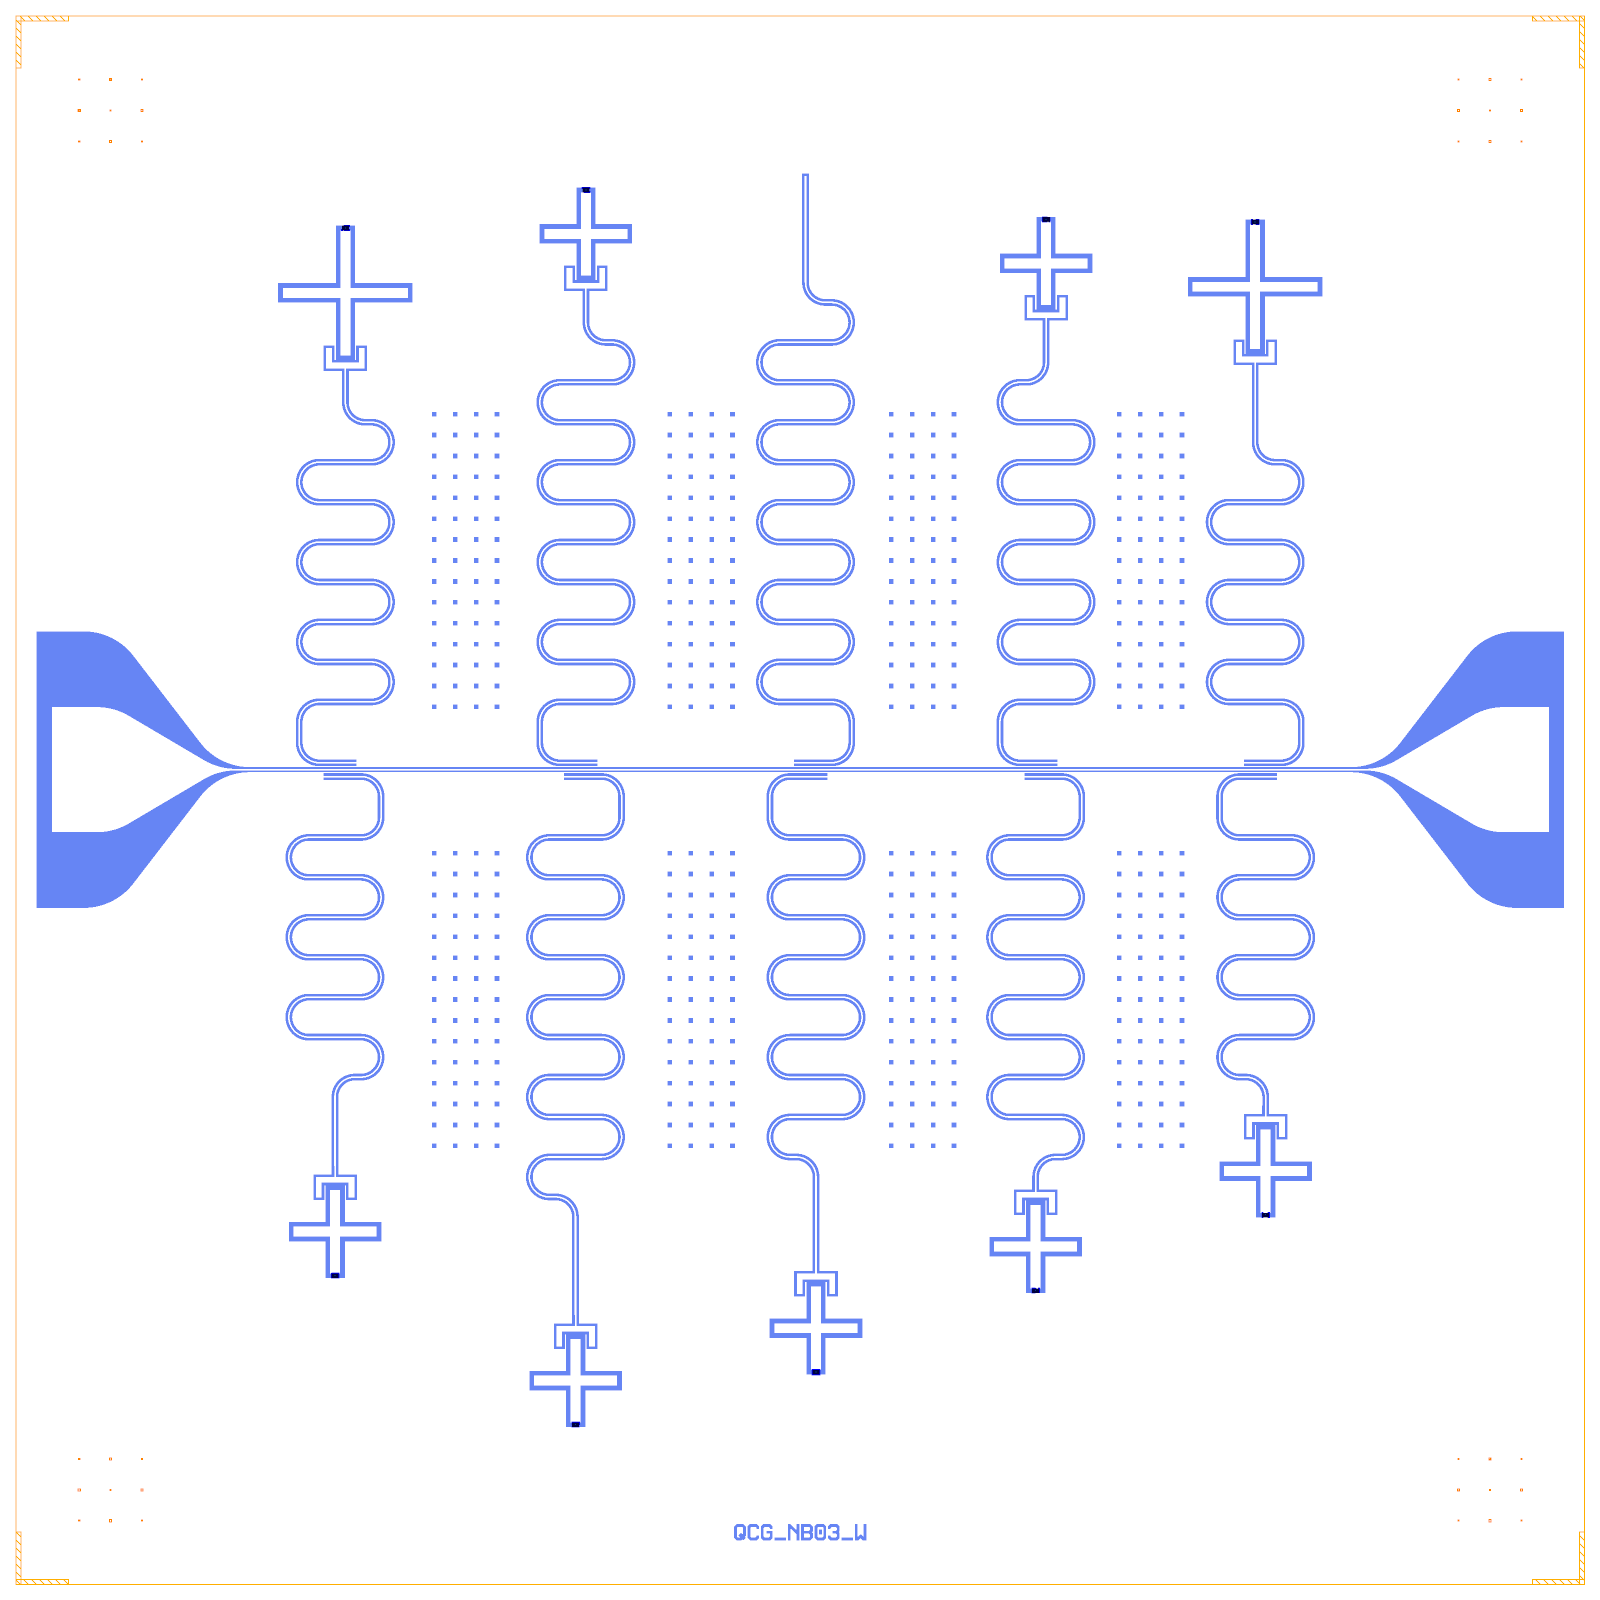

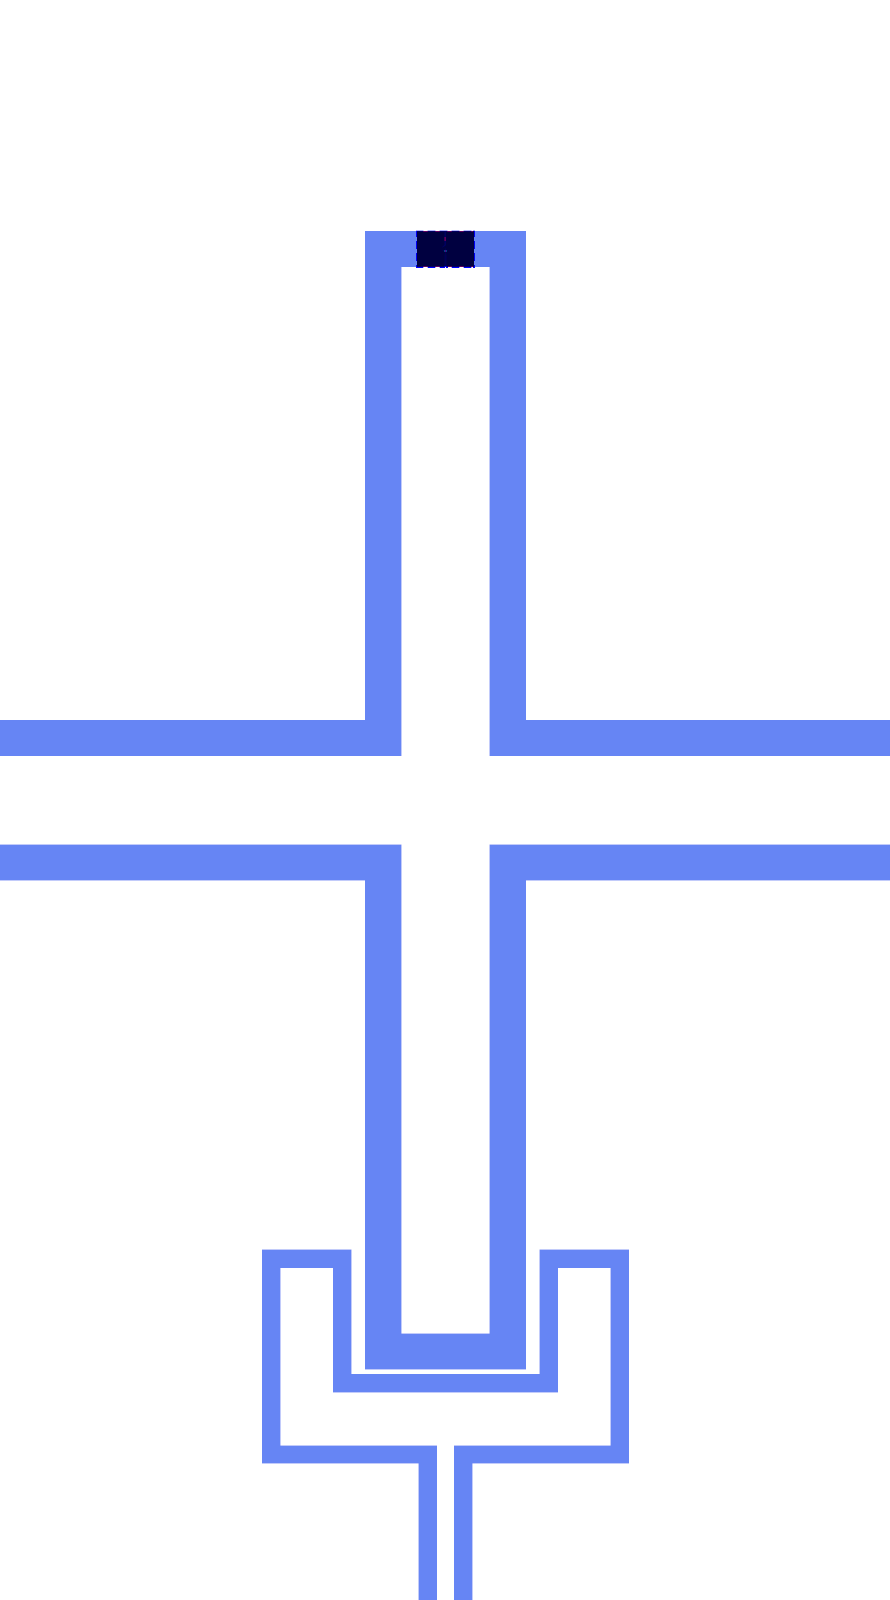

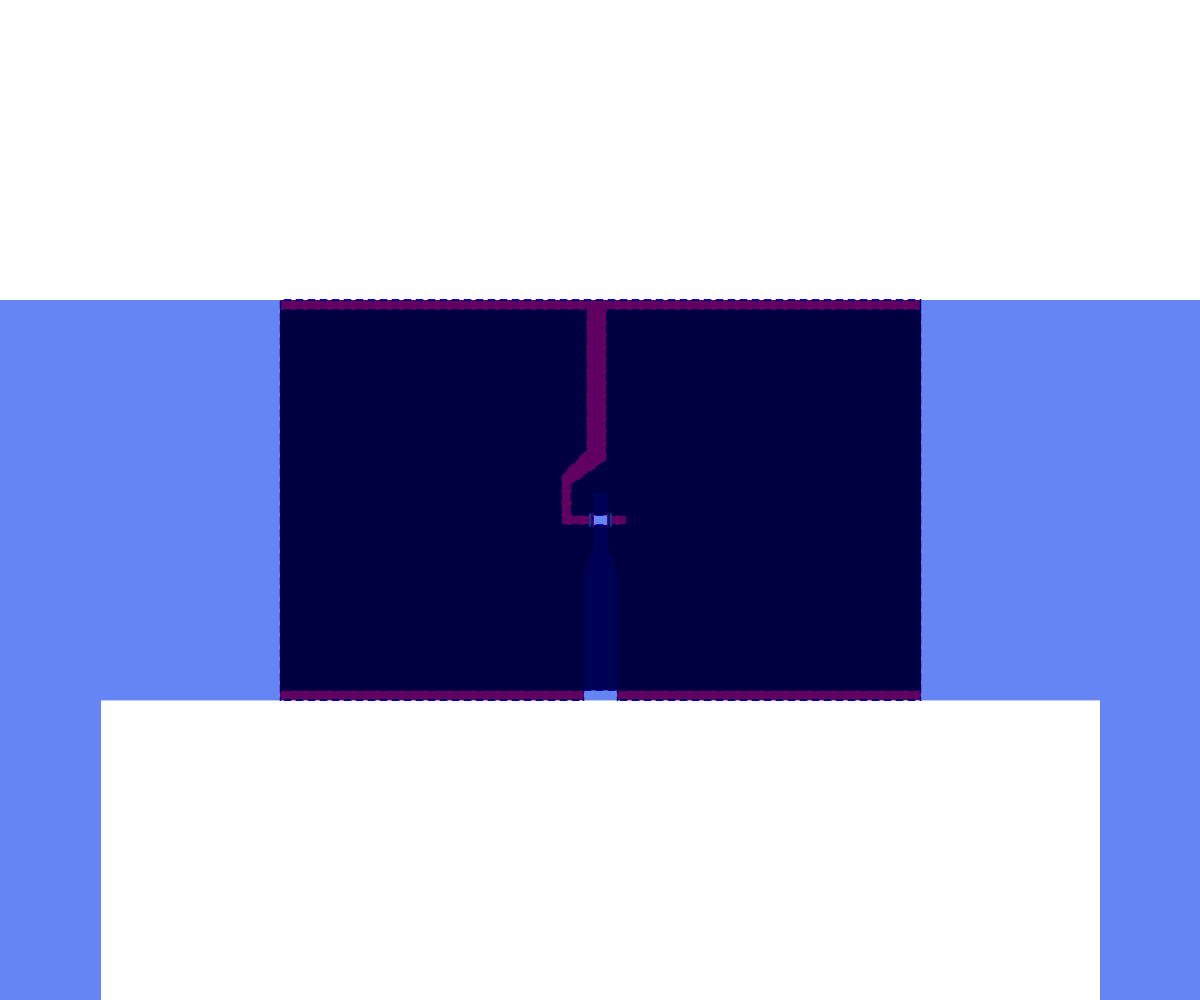

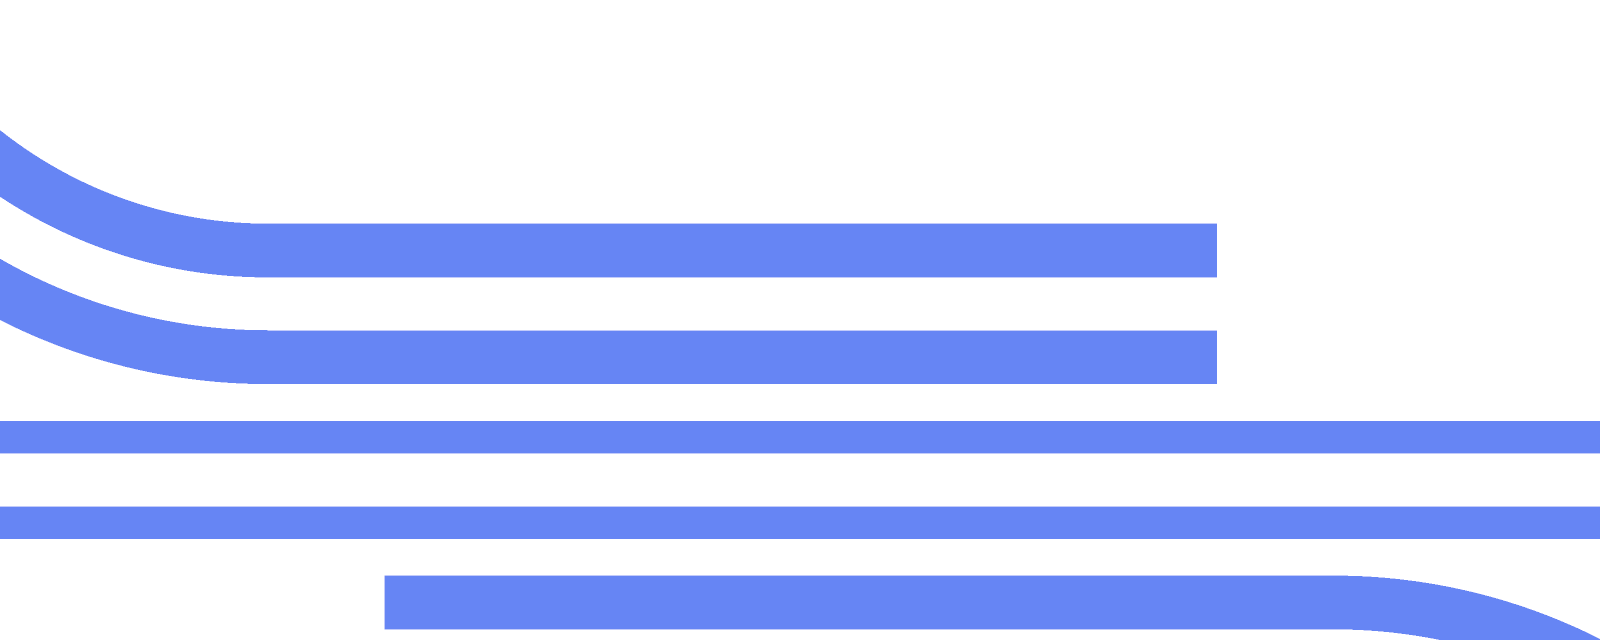

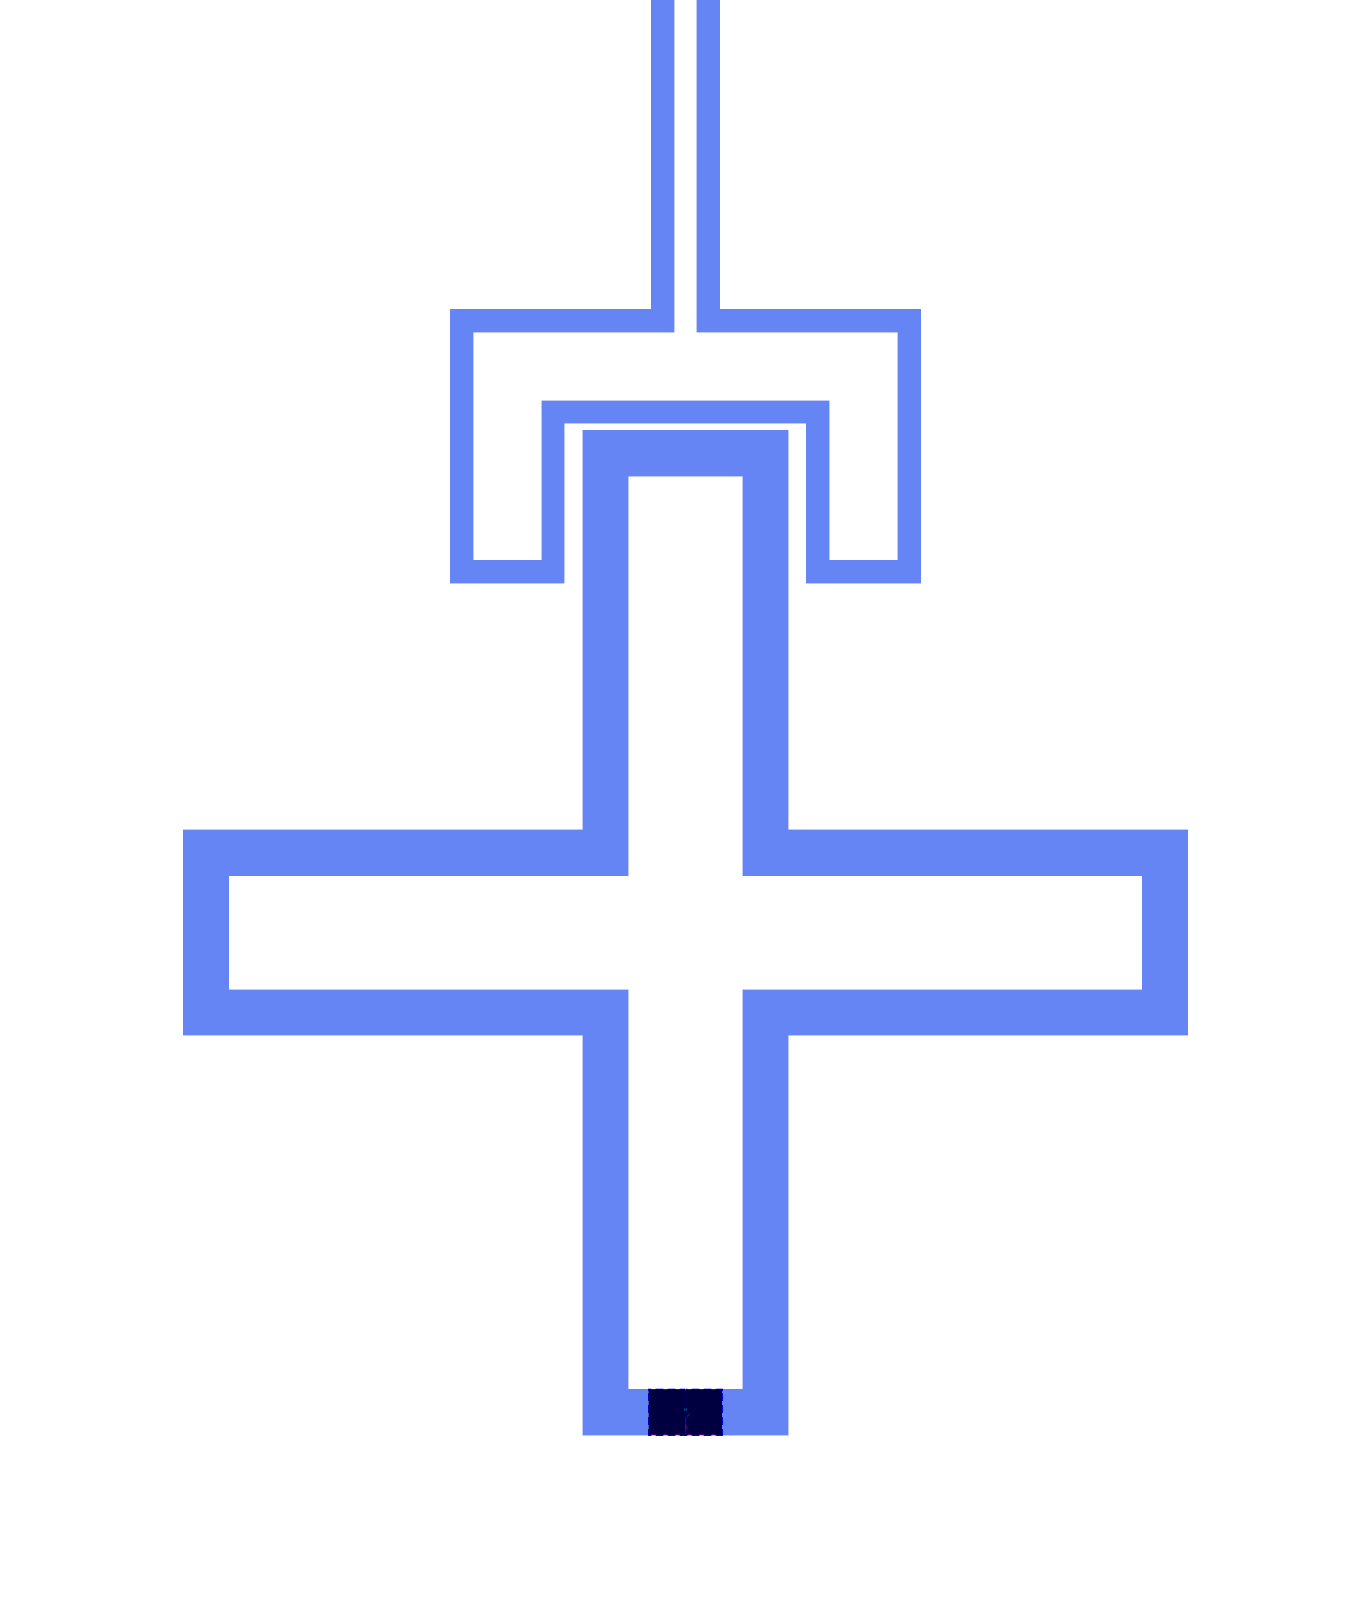

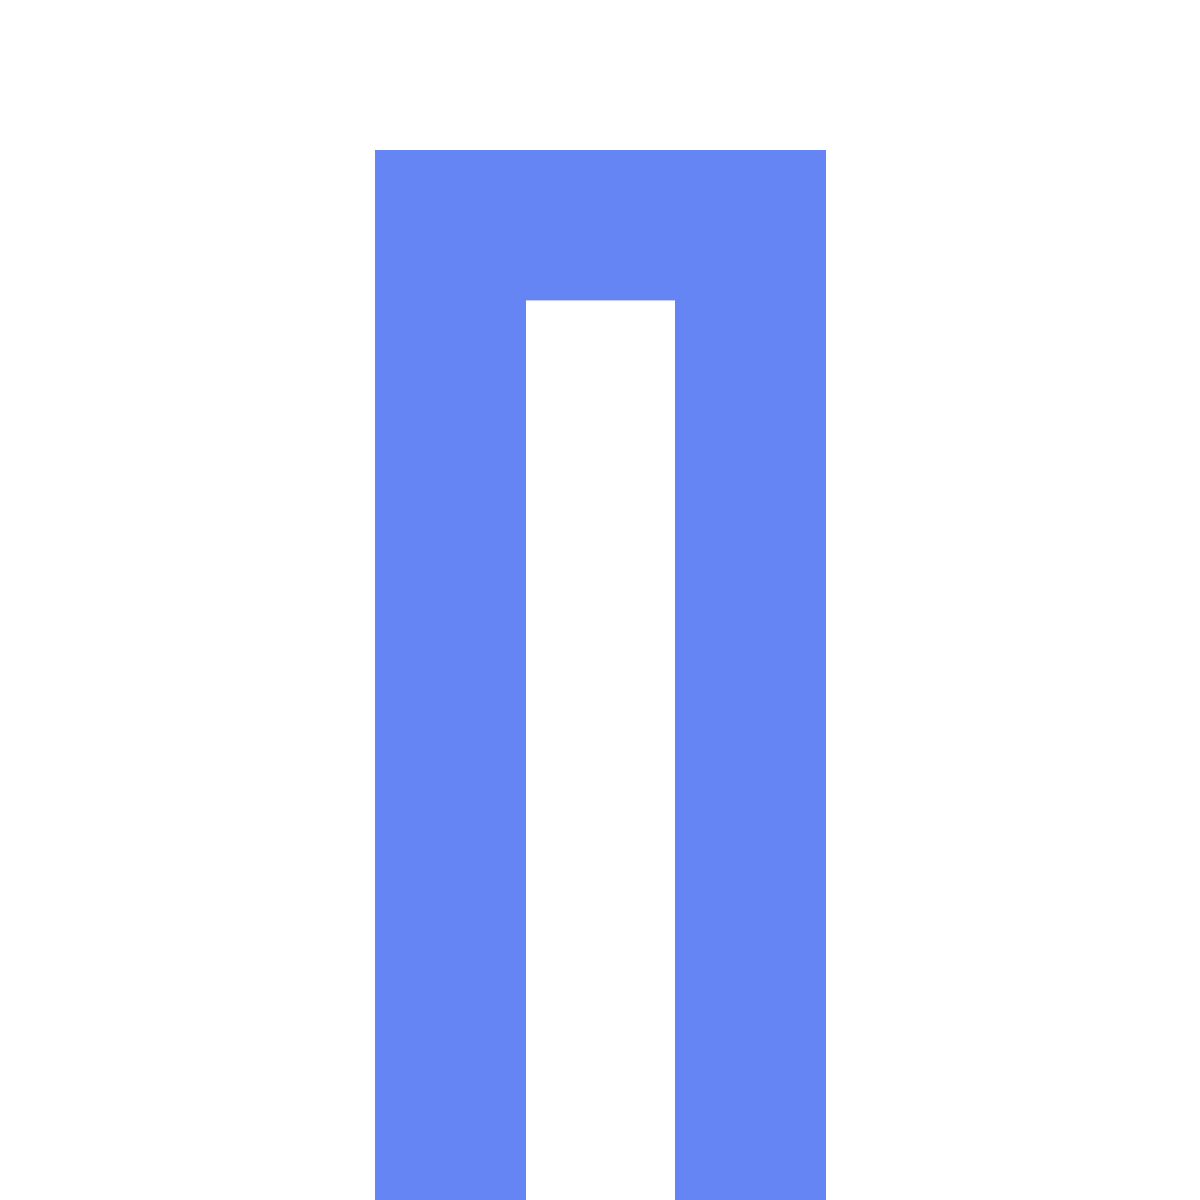

WindowsPath('examples/designs/legacy/chip_03_trilayer_r7end.png')

In [16]:
X1, Y1 = L.origin(d, "Q1")              # Q1 centre (Designer frame, snapped to R1's tail)
X6, Y6 = L.origin(d, "Q6")
X7, Y7 = C.port_xy(d, "R7.end")
XC = C.port_xy(d, "FL.a")[1]            # feedline y after centring
C.show_snapshot(d, OUT / f"{ID}.png")
C.show_snapshot(d, OUT / f"{ID}_q1.png", box=(X1 - 250, Y1 - 450, X1 + 250, Y1 + 450), size=(890, 1600), width=360)
C.show_snapshot(d, OUT / f"{ID}_jj.png", box=(X1 - 30, Y1 + 285, X1 + 30, Y1 + 335), size=(1200, 1000), width=400)
C.show_snapshot(d, OUT / f"{ID}_coupler.png", box=(1400, XC - 30, 1700, XC + 90), size=(1600, 640))
C.show_snapshot(d, OUT / f"{ID}_q6.png", box=(X6 - 300, Y6 - 292, X6 + 300, Y6 + 408), size=(1370, 1600), width=400)
C.show_snapshot(d, OUT / f"{ID}_r7end.png", box=(X7 - 40, Y7 - 60, X7 + 40, Y7 + 20), size=(1200, 1200), width=360)

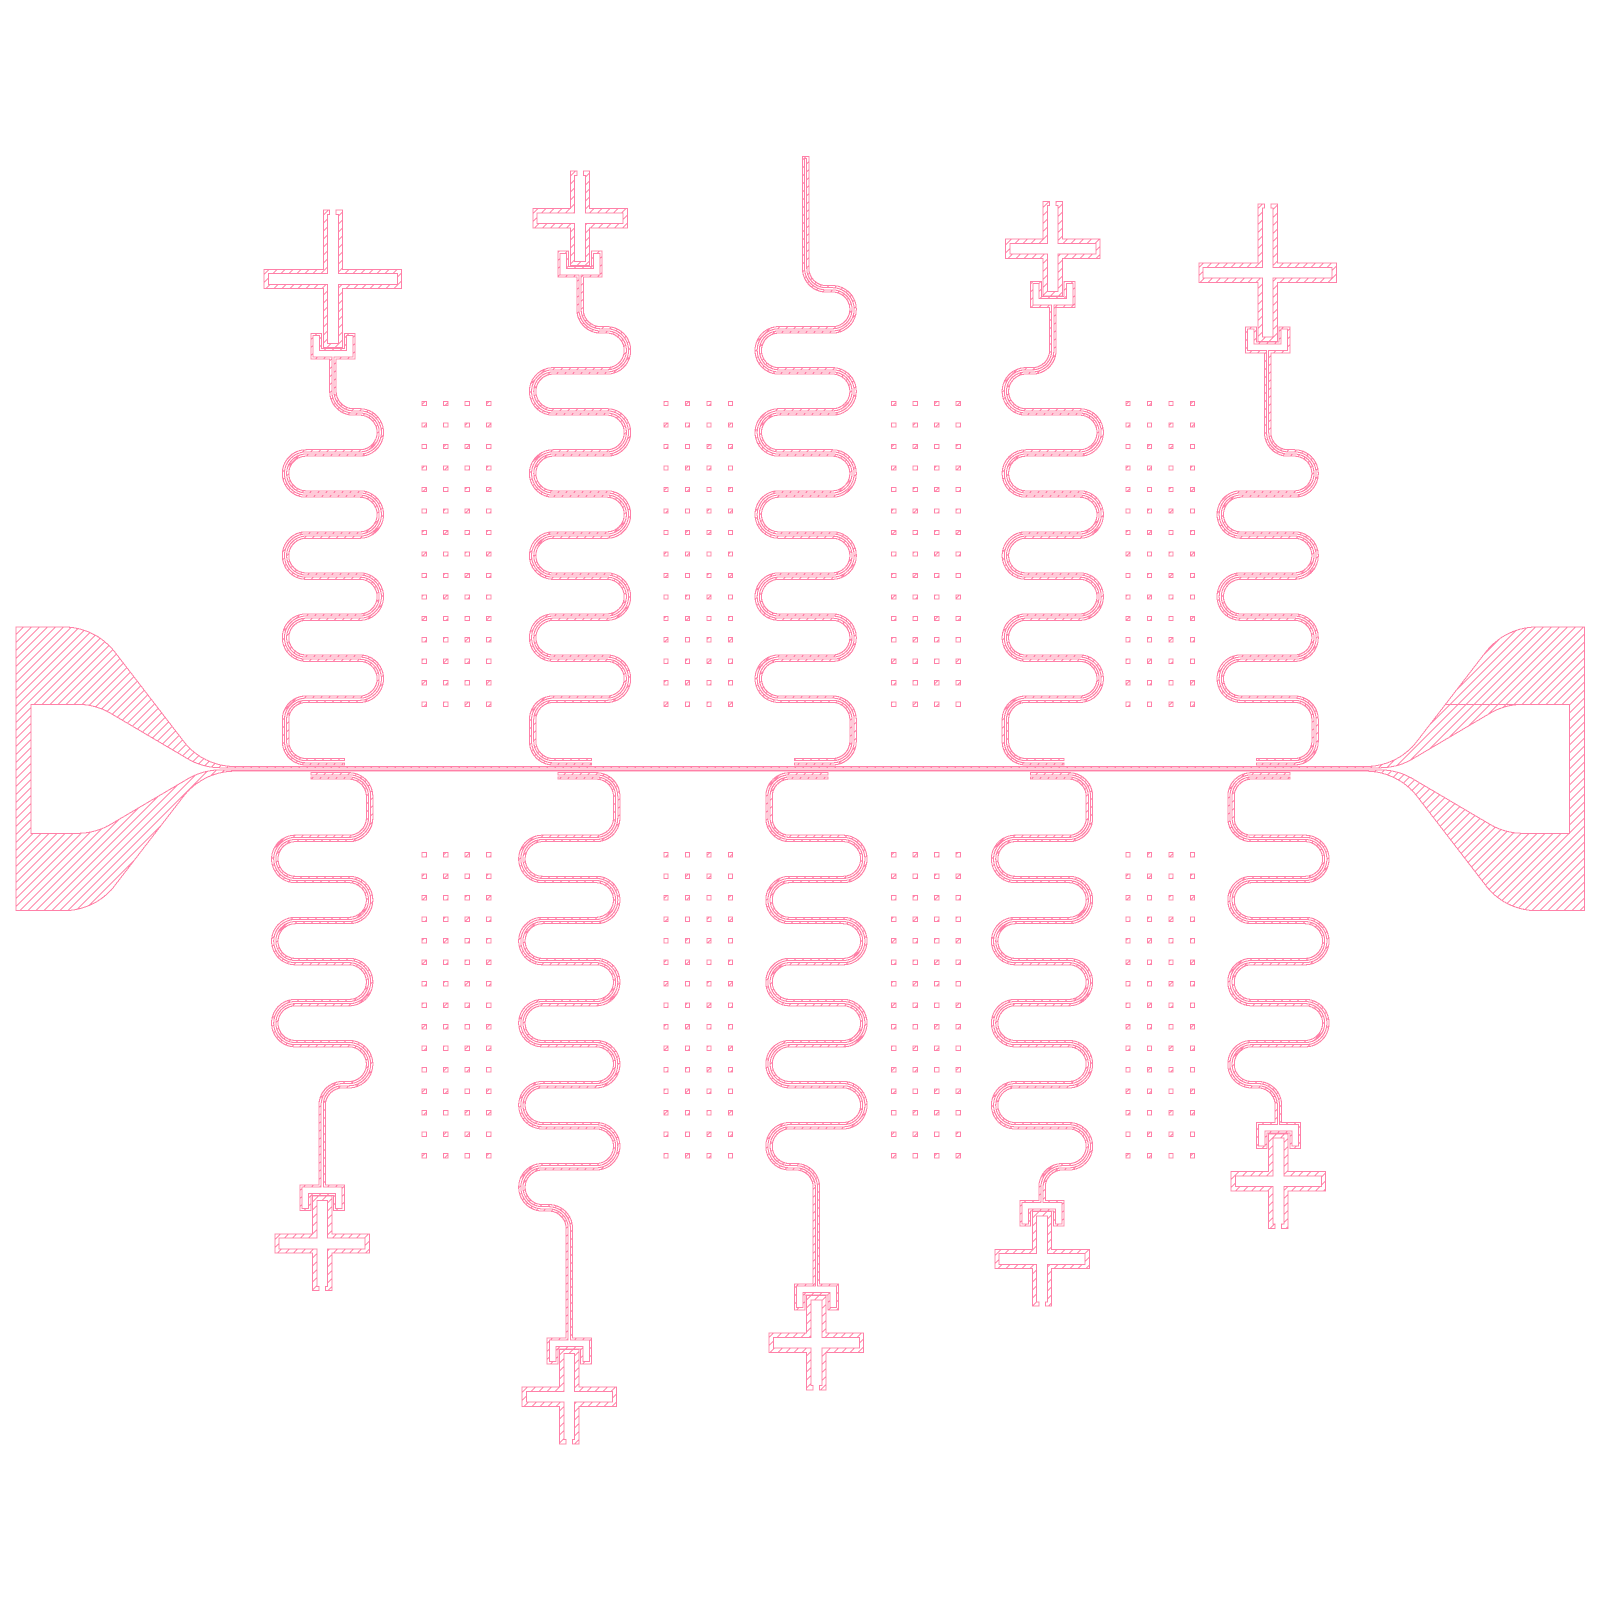

| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| FL | 61920 | 61920 | 0.0 | 0.00% |
| P1 | 493800 | 493800 | 0.0 | 0.00% |
| P2 | 493800 | 493800 | 0.0 | 0.00% |
| R1 | 94359 | 94359 | 0.0 | 0.00% |
| R2 | 87759 | 87759 | 0.0 | 0.00% |
| R5 | 116359 | 116359 | 0.0 | 0.00% |
| R6 | 123559 | 123559 | 0.0 | 0.00% |
| R7 | 135659 | 135659 | 0.0 | 0.00% |
| R8 | 111359 | 111359 | 0.0 | 0.00% |
| R9 | 106359 | 106359 | 0.0 | 0.00% |
| R10 | 103559 | 103559 | 0.0 | 0.00% |
| R11 | 87759 | 87759 | 0.0 | 0.00% |
| R12 | 81959 | 81959 | 0.0 | 0.00% |
| Q1 | 57220 | 57820 | 600.0 | 1.05% |
| Q2 | 41220 | 41820 | 600.0 | 1.46% |
| Q5 | 41220 | 41820 | 600.0 | 1.46% |
| Q6 | 41220 | 41820 | 600.0 | 1.46% |
| Q8 | 41220 | 41820 | 600.0 | 1.46% |
| Q9 | 41220 | 41820 | 600.0 | 1.46% |
| Q10 | 41220 | 41820 | 600.0 | 1.46% |
| Q11 | 57220 | 57820 | 600.0 | 1.05% |
| Q12 | 41220 | 41820 | 600.0 | 1.46% |
| H0N | 24000 | 24000 | 0.0 | 0.00% |
| H0S | 24000 | 24000 | 0.0 | 0.00% |
| H1N | 24000 | 24000 | 0.0 | 0.00% |
| H1S | 24000 | 24000 | 0.0 | 0.00% |
| H2N | 24000 | 24000 | 0.0 | 0.00% |
| H2S | 24000 | 24000 | 0.0 | 0.00% |
| H3N | 24000 | 24000 | 0.0 | 0.00% |
| H3S | 24000 | 24000 | 0.0 | 0.00% |

max XOR without the Xmons (junction windows): 0.0 µm²


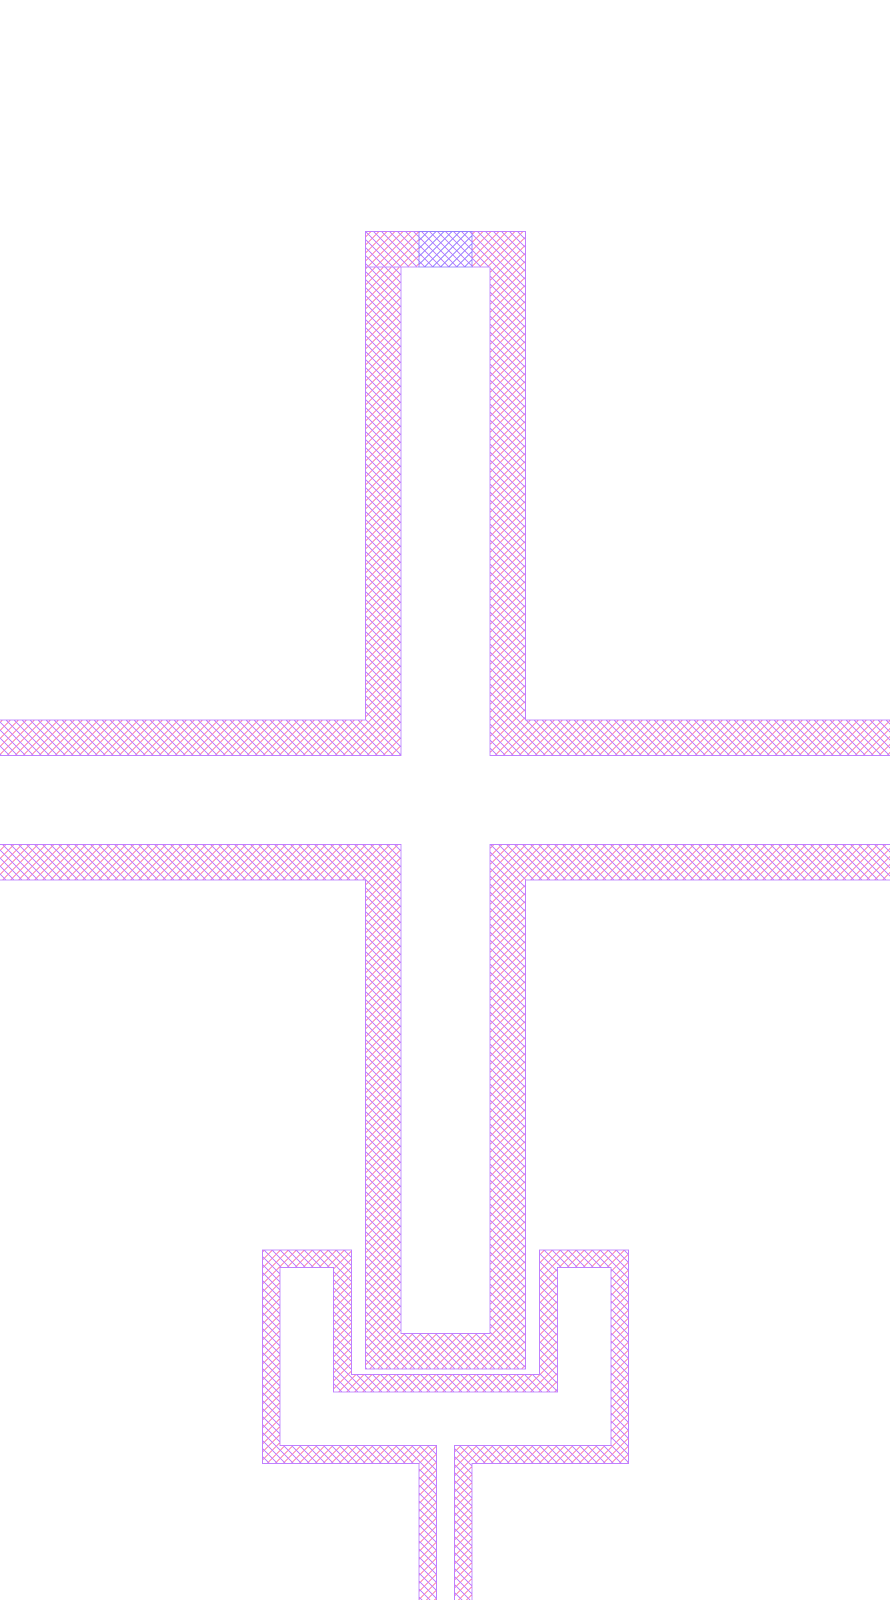

In [17]:
if L.legacy_available():
    YQ = {n: L.origin(d, f"Q{n}")[1] - L.H / 2 - SHIFT[1] for n, *_, q in ROWS if q}   # corrected (#8), legacy frame
    sgn = lambda n: 1 if YQ[n] > 0 else -1
    tip = lambda n, q: YQ[n] + sgn(n) * (300 if q[3] else 200)                          # cross tip behind the junction
    ref = L.xmon_feedline_reference(
        ID, feed=FEED | {"length": 2 * x_pad}, pads=[(PAD, -x_pad, 0, 3), (PAD, x_pad, 0, 1)],   # PDK pad position
        resonators=[(f"R{n}", RES | {"cpw_len": length, "flip": flip, "ground": q is None}, x, y, 0, mirror)
                    for n, x, y, mirror, length, flip, f, q in ROWS],
        xmons=[(f"Q{n}", BIG if q[3] else XMON, q[0], YQ[n], q[2], False) for n, *_, q in ROWS if q],
        etches=[(f"H{k}{side}", [(x + 450 + i * 100 - 10, y0 + j * 100 - 10, x + 450 + i * 100 + 10, y0 + j * 100 + 10)
                                 for i in range(4) for j in range(15)])
                for k, x in enumerate(HOLES_X) for side, y0 in (("N", 300), ("S", -1800))],
        cutters=[(q[0] - 15, tip(n, q) + 7 * sgn(n) - 13.5, q[0] + 15, tip(n, q) + 7 * sgn(n) + 13.5)
                 for n, *_, q in ROWS if q])
    ref = L.shift_reference(ref, *SHIFT)
    from quantcore_circuits.live.snapshot import snapshot
    snapshot(ref.write(f"build/legacy_a/{ID}_legacy.oas"), OUT / f"{ID}_legacy.png")
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref)
    display(Markdown(table))
    print("max XOR without the Xmons (junction windows):",
          round(max(v for k, v in xor.items() if not k.startswith("Q")), 3), "µm²")
    L.xor_png(d, ref, OUT / f"{ID}_xor_q1.png", box=(X1 - 250, Y1 - 450, X1 + 250, Y1 + 450), size=(890, 1600))
    display(Image(filename=str(OUT / f"{ID}_xor_q1.png"), width=360))
else:
    print("components/ (legacy library) not present: no legacy reference")

## 15 · Summary

- **Matches the source:** the ten resonators, nine Xmon crosses and claws (corrected #8), R7 uncut (#26), the
  flux-hole arrays, and the pads + feedline at their PDK position (XOR 0 µm² except the Xmons' junction windows).
- **Differs, by the PDK:** pads `pad_edge` = 100 µm from the die edge (feedline 5160 µm), the circuit centred
  (+146 µm in y), the PDK frame and device ID `QCG_Nb03_W`.
- **Cheese:** the PDK cheese over the whole die (`cheese: "chip"`, fab cheese source "build") plus the original's flux holes.
- **Open:** 9 `pdk_rn` design warnings (33.7 / 54.0 kΩ); Q9/R9 and Q10/R10 collide (R9 4940 µm separates Q9:
  χ 45 → −5.4 MHz).